In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np 
import pandas as pd
import json 
from matplotlib import pyplot as plt 
import pickle
from botorch.utils.transforms import standardize

torch.set_default_dtype(torch.float64)

tkwargs = {"dtype": torch.double,
           "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")}

np.random.seed(42)
torch.manual_seed(42)

In [2]:
with open("./experiment.json", "r") as f:
    exp_data = json.load(f)
exp_data = pd.DataFrame(exp_data)

processed_mass_data = {}
with open("mass_data.pickle", "rb") as f:
    mass_data = pickle.load(f)
with open("current_all.pickle", "rb") as f:
    current_all = pickle.load(f)
for i in mass_data:
    processed_mass_data[list(i.keys())[0]] = list(i.values())[0]
    
error_index = open("异常序号.txt", "r").readlines()[1:]
error_index = [int(i.replace('\n', '')) for i in error_index]

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.3463]), std = tensor([0.4994])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.9769]), std = tensor([5.6190e-06])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


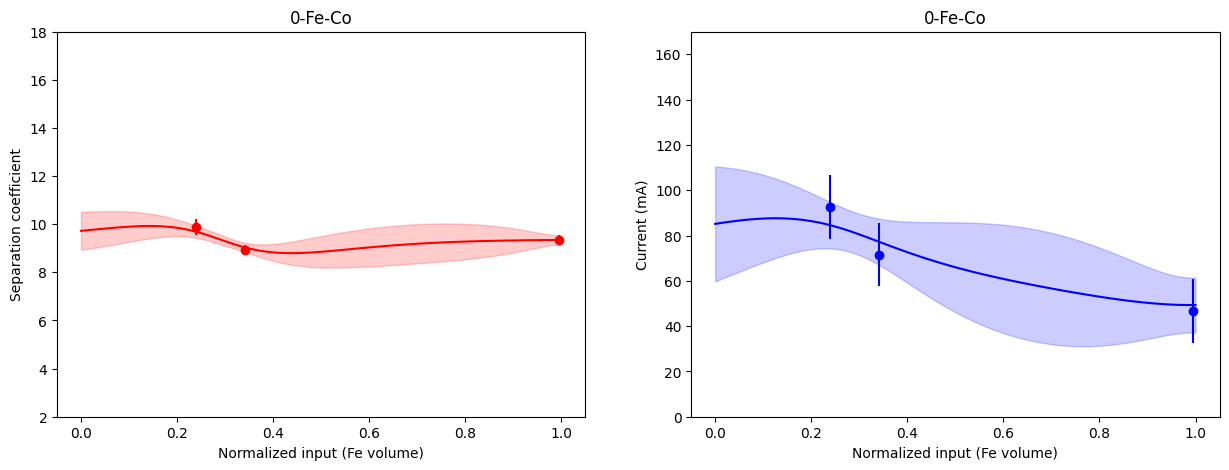

In [ ]:
model_total = {}
failures = []
for i in range(int(len(mass_data)/4)):
    # read in the data
    x = []
    y_mean = []
    y_var = []
    y_current_mean = []
    y_current_var = []
    if (len(exp_data.iloc[4*i:4*i+4]["substance2"].unique()) == 1) and (len(exp_data.iloc[4*i:4*i+4]["substance1"].unique()) == 1):
        pass
    else:
        raise ValueError(i)
    # read in the data 
    for j in range(4*i,4*i+4):
        if (j not in error_index):
            x.append((exp_data.iloc[j]["volume1"]/20 - 0.025)/0.95)
            if len(processed_mass_data[j]) == 0:
                raise ValueError(j)
            if (j not in list(processed_mass_data.keys())):
                raise ValueError(j)
                
            y_mean.append(processed_mass_data[j].flatten().mean())
            y_var.append(processed_mass_data[j].flatten().var())
            y_current_mean.append(current_all[j].flatten().mean())
            y_current_var.append(current_all[j].flatten().var())
            
    # process the data input numpy array
    x = np.array(x).reshape(-1,1)
    y_mean = np.array(y_mean).reshape(-1,1)
    y_var = np.array(y_var).reshape(-1,1)
    y_current_mean = np.array(y_current_mean).reshape(-1,1)
    y_current_var = np.array(y_current_var).reshape(-1,1) + 198.53163497959181
    
    # if the data is not empty, perform machine learning
    if len(x)>0:
        # initialize the machine learning models for 
        train_x = torch.tensor(x).reshape(-1,1)
        train_y = torch.tensor(np.concatenate([y_mean,y_current_mean], axis = 1))
        train_y_var = torch.tensor(np.concatenate([y_var,y_current_var], axis = 1))
        # initialize the model 
        mll, model = botorch_tool.tools.initialize_heter_noise_model(train_x = train_x,
                                                                     train_obj = train_y,
                                                                     train_obj_var = train_y_var)
        # fit the model
        try:
            fit_gpytorch_mll(mll)
        except:
            failures.append(i)
            try:
                # initialize the noiseless model (not really noiseless, because the noise is estimated by the means)
                mll, model = botorch_tool.tools.initialize_noiseless_model(train_x = train_x,
                                                                           train_obj = train_y)
                fit_gpytorch_mll(mll)
            except:
                continue
        
        # show the prediction of the machine learning models
        x_plot = torch.tensor(np.linspace(0,1,101))
        preidct = model.posterior(x_plot).mean.detach().numpy()
        std = np.sqrt(model.posterior(x_plot).variance.detach().numpy())
        substance1 = exp_data.iloc[j]["substance1"]
        substance2 = exp_data.iloc[j]["substance2"]

        # plot the results from the prediction 
        fig, axs = plt.subplots(1, 2, figsize=(15, 5))
        # plot the coefficient of H/D splitting 
        axs[0].plot(x_plot, preidct[:,0], color = "red")
        axs[0].fill_between(x_plot, preidct[:,0] + std[:,0], preidct[:,0] - std[:,0],color='red', alpha=0.2)
        axs[0].scatter(train_x, 
                    train_y[:,0],
                    color = "red")
        axs[0].errorbar(train_x.flatten(), 
                     train_y[:,0].flatten(), 
                     yerr = np.sqrt(train_y_var[:,0].flatten()), 
                     xerr = None,  
                     color = "red",
                     ls='none')
        axs[0].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[0].set_ylabel("Separation coefficient")
        axs[0].set_ylim(2,18)
        axs[0].set_title(f"{i}-" + substance1 + "-" + substance2)

        # show the plot for the second prediction 
        axs[1].plot(x_plot, preidct[:,1], color = "blue")
        axs[1].fill_between(x_plot, preidct[:,1] + std[:,1], preidct[:,1] - std[:,1], color='blue', alpha=0.2)
        axs[1].scatter(train_x, 
                    train_y[:,1],
                    color = "blue")
        axs[1].errorbar(train_x.flatten(), 
                     train_y[:,1].flatten(), 
                     yerr = np.sqrt(train_y_var[:,1].flatten()), 
                     xerr = None,
                     color = "blue",
                     ls='none')
        axs[1].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[1].set_ylabel("Current (mA)")
        axs[1].set_ylim(0, max(170, max(preidct[:,1] + std[:,1])))

        axs[1].set_title(f"{i}-" + substance1 + "-" + substance2)
        plt.show()
        plt.close()
        
        # append the model to the total model list 
        model_total[f"{i}-" + substance1 + "-" + substance2] = model
        # get the candidate 
        MC_SAMPLES = 1024
        sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))
        candidate = botorch_tool.tools.optimize_qnehvi_and_get_observation(
            model = model, 
            train_x = train_x, 
            ref_point = [0,0],
            sampler = sampler)
        model_total[f"{i}-" + substance1 + "-" + substance2 + "_x"] = candidate
